# Visualisation et inspection des données — Élections communales au Maroc (2015 vs 2021)

**Responsable 2 : Visualisation et développement applicatif**

Contenu du notebook :
1. Configuration et chargement
2. Inspection des données
3. Dictionnaire des colonnes (exporté en CSV)
4. Analyse descriptive complémentaire
5. Graphiques statistiques
6. Cartographie
7. Export des données pour le dashboard Streamlit

## 1. Configuration et chargement

In [20]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

# Chemins (le notebook est dans Script/notebooks/)
BASE_DIR = Path.cwd().parent.parent
DATA_PROCESSED = BASE_DIR / "Data" / "processed"
RESULTATS = BASE_DIR / "Script" / "resultats"
FIG_DIR = RESULTATS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    # Sauvegarde une figure Plotly en HTML (et en PNG si kaleido est installé)
    fig.write_html(FIG_DIR / f"{name}.html")
    try:
        fig.write_image(FIG_DIR / f"{name}.png", scale=2)
    except Exception as e:
        print(f"PNG non exporté pour {name} (pip install kaleido) : {type(e).__name__}")


print("BASE_DIR       :", BASE_DIR)
print("DATA_PROCESSED :", DATA_PROCESSED)
print("RESULTATS      :", RESULTATS)

BASE_DIR       : c:\Users\DELL\Desktop\Projet-Election
DATA_PROCESSED : c:\Users\DELL\Desktop\Projet-Election\Data\processed
RESULTATS      : c:\Users\DELL\Desktop\Projet-Election\Script\resultats


In [21]:
df_communes = pd.read_csv(DATA_PROCESSED / "kharita_communes_nettoye.csv")
print("Dimensions :", df_communes.shape)
display(df_communes.head())

Dimensions : (3006, 71)


,tie,year,votes_mp,votes_pa,votes_pe,votes_pi,votes_uc,votes_afg,votes_agd,votes_ahd,votes_ffd,votes_mds,votes_neo,votes_pam,votes_pan,votes_pcs,votes_pdi,votes_pdn,votes_pe2,votes_pgv,votes_pjd,votes_pml,votes_pps,votes_prd,votes_pre,votes_prv,votes_psd,votes_psu,votes_pud,votes_pvm,votes_rni,votes_sap,votes_umd,commune_ar,lead_party,lead_votes,votes_pedd,votes_pljs,votes_pml1,votes_sap2,votes_sap3,votes_usfp,region_code,region_name,seats_total,turnout_pct,votes_total,commune_code,commune_name,commune_type,lead_parties,election_date,province_code,province_name,lead_share_pct,aggregation_type,women_elected_pct,source_commune_ids,elected_age_ge55_pct,elected_age_le34_pct,elected_age_35_44_pct,elected_age_45_54_pct,elected_higher_edu_pct,geometry_wkt,vote_fields_reported,vote_fields_available,vote_coverage_pct,observed_party_votes,party_concentration,winning_margin,number_of_parties
0,False,2015,1223,0,0,1101,0,NaN,56.000,358,14,0,0,172,0,0,0,0,NaN,3.000,347,0.000,257,0,0.000,0,0,NaN,0,NaN,2704,0,0,افورار,RNI,2704,1,0,NaN,0,NaN,447,5,Beni-Mellal - Khénifra,27.000,63.420,6683,05.081.11.01,Afourar,H,RNI,2015-09-04,5.081,Azilal,40.460,commune_source,NaN,1135,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON(((-6.57154104499995 32.177193145,...",31,31,100.000,"6,683.000",0.237,0.222,12.000
1,False,2015,320,0,0,600,0,NaN,197.000,0,0,19,0,1695,0,0,0,0,NaN,0.000,0,0.000,193,0,0.000,0,0,NaN,0,NaN,582,0,0,اكودي نلخير,PAM,1695,0,0,NaN,0,NaN,0,5,Beni-Mellal - Khénifra,17.000,77.150,3606,05.081.03.01,Agoudi N'Lkhair,R,PAM,2015-09-04,5.081,Azilal,47.000,commune_source,NaN,1136,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON(((-6.46598052899992 32.055786809,...",31,31,100.000,"3,606.000",0.288,0.304,7.000
2,False,2015,698,0,0,0,0,NaN,55.000,0,0,450,0,219,0,0,0,0,NaN,0.000,1643,0.000,0,0,0.000,0,0,NaN,0,NaN,0,0,0,أيت عباس,PJD,1643,0,0,NaN,0,NaN,145,5,Beni-Mellal - Khénifra,19.000,67.450,3210,05.081.03.03,Ait Abbas,R,PJD,2015-09-04,5.081,Azilal,51.180,commune_source,NaN,1130,NaN,NaN,NaN,NaN,NaN,MULTIPOLYGON(((-6.68305837299994 31.8257562540...,31,31,100.000,"3,210.000",0.336,0.294,6.000
3,False,2015,0,0,0,0,0,NaN,0.000,0,0,1164,0,0,0,0,0,0,NaN,0.000,263,0.000,0,0,0.000,0,0,NaN,0,NaN,0,0,0,أيت بلال,MDS,1164,0,0,NaN,0,NaN,627,5,Beni-Mellal - Khénifra,17.000,66.220,2054,05.081.15.01,Ait Blal,R,MDS,2015-09-04,5.081,Azilal,56.670,commune_source,NaN,1125,NaN,NaN,NaN,NaN,NaN,MULTIPOLYGON(((-6.76051183999993 31.7131149310...,31,31,100.000,"2,054.000",0.431,0.261,3.000
4,False,2015,0,0,0,0,0,NaN,0.000,0,0,0,0,1197,0,0,0,0,NaN,0.000,0,0.000,0,0,0.000,0,0,NaN,0,NaN,1243,0,0,أيت بوعلي,RNI,1243,0,0,NaN,0,NaN,0,5,Beni-Mellal - Khénifra,17.000,64.690,2440,05.081.03.05,Ait Bou Oulli,R,RNI,2015-09-04,5.081,Azilal,50.940,commune_source,NaN,1127,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON(((-6.49549669999993 31.664675812,...",31,31,100.000,"2,440.000",0.500,0.019,2.000


In [22]:
# Vérification de l'échelle des pourcentages : certaines colonnes peuvent être en fraction (0-1)
# alors qu'elles sont nommées "_pct". On les ramène toutes en pourcentage (0-100).
cols_pct = [
    "turnout_pct", "lead_share_pct", "women_elected_pct",
    "elected_age_ge55_pct", "elected_age_le34_pct", "elected_age_35_44_pct",
    "elected_age_45_54_pct", "elected_higher_edu_pct",
]
for c in cols_pct:
    mx = df_communes[c].max()
    if pd.notna(mx) and mx <= 1.5:
        df_communes[c] = df_communes[c] * 100
        print(f"{c} : converti de fraction en % (max avant = {mx:.3f})")
    else:
        print(f"{c} : déjà en % (max = {mx:.2f})")

# winning_margin et party_concentration restent des fractions (0-1) : c'est leur définition

turnout_pct : déjà en % (max = 93.24)
lead_share_pct : déjà en % (max = 100.00)
women_elected_pct : déjà en % (max = 43.75)
elected_age_ge55_pct : déjà en % (max = 85.71)
elected_age_le34_pct : déjà en % (max = 62.50)
elected_age_35_44_pct : déjà en % (max = 72.22)
elected_age_45_54_pct : déjà en % (max = 68.75)
elected_higher_edu_pct : déjà en % (max = 85.71)


## 2. Inspection des données

In [23]:
print("Années présentes :", sorted(df_communes["year"].unique()))
print("Nombre de communes par année :")
print(df_communes["year"].value_counts().sort_index())
print("\nCommunes uniques (commune_code) :", df_communes["commune_code"].nunique())
print("Régions :", df_communes["region_name"].nunique())
print("Provinces :", df_communes["province_name"].nunique())

Années présentes : [np.int64(2015), np.int64(2021)]
Nombre de communes par année :
year
2015    1503
2021    1503
Name: count, dtype: int64

Communes uniques (commune_code) : 1503
Régions : 12
Provinces : 75


In [24]:
df_communes.info()

<class 'pandas.DataFrame'>
RangeIndex: 3006 entries, 0 to 3005
Data columns (total 71 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   tie                     3006 non-null   bool   
 1   year                    3006 non-null   int64  
 2   votes_mp                3006 non-null   int64  
 3   votes_pa                3006 non-null   int64  
 4   votes_pe                3006 non-null   int64  
 5   votes_pi                3006 non-null   int64  
 6   votes_uc                3006 non-null   int64  
 7   votes_afg               1503 non-null   float64
 8   votes_agd               1503 non-null   float64
 9   votes_ahd               3006 non-null   int64  
 10  votes_ffd               3006 non-null   int64  
 11  votes_mds               3006 non-null   int64  
 12  votes_neo               3006 non-null   int64  
 13  votes_pam               3006 non-null   int64  
 14  votes_pan               3006 non-null   int64  
 15

In [25]:
display(df_communes.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tie,3006,2,False,3004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,"3,006.000",NaN,NaN,NaN,"2,018.000",3.000,"2,015.000","2,015.000","2,018.000","2,021.000","2,021.000"
votes_mp,"3,006.000",NaN,NaN,NaN,394.708,881.733,0.000,0.000,37.000,397.000,"12,564.000"
votes_pa,"3,006.000",NaN,NaN,NaN,3.681,48.192,0.000,0.000,0.000,0.000,"1,898.000"
votes_pe,"3,006.000",NaN,NaN,NaN,6.506,60.148,0.000,0.000,0.000,0.000,"1,624.000"
votes_pi,"3,006.000",NaN,NaN,NaN,784.460,"1,527.534",0.000,73.000,394.500,"1,022.750","35,076.000"
votes_uc,"3,006.000",NaN,NaN,NaN,272.253,"1,102.980",0.000,0.000,0.000,126.000,"39,664.000"
votes_afg,"1,503.000",NaN,NaN,NaN,44.493,259.973,0.000,0.000,0.000,0.000,"6,395.000"
votes_agd,"1,503.000",NaN,NaN,NaN,66.778,264.659,0.000,0.000,0.000,0.000,"4,532.000"
votes_ahd,"3,006.000",NaN,NaN,NaN,13.355,123.765,0.000,0.000,0.000,0.000,"3,075.000"


In [26]:
missing = pd.DataFrame({
    "Valeurs manquantes": df_communes.isnull().sum(),
    "Pourcentage": df_communes.isnull().mean() * 100,
}).sort_values("Pourcentage", ascending=False)

display(missing[missing["Valeurs manquantes"] > 0])

,Valeurs manquantes,Pourcentage
women_elected_pct,1509,50.200
elected_age_le34_pct,1509,50.200
elected_age_35_44_pct,1509,50.200
elected_age_ge55_pct,1509,50.200
elected_age_45_54_pct,1509,50.200
elected_higher_edu_pct,1509,50.200
votes_afg,1503,50.000
votes_pml1,1503,50.000
votes_sap3,1503,50.000
votes_pgv,1503,50.000


### Lecture des valeurs manquantes

- **Colonnes de partis** (`votes_afg`, `votes_agd`, `votes_pe2`, `votes_pgv`, ...) : environ 50 % de NaN. Ce sont des **NaN structurels** : le parti n'existe que pour une des deux années. Ce ne sont pas des erreurs.
- **Profil des élus** (`women_elected_pct`, `elected_age_*`, `elected_higher_edu_pct`) : disponible seulement pour une année (2021).
- `turnout_pct`, `seats_total` : quelques valeurs manquantes à signaler dans les analyses.
- `commune_ar` : 2 noms arabes manquants. Utiliser `commune_code` comme identifiant.

In [27]:
# Quels partis existent à quelle année ? (True = au moins une valeur non nulle)
cols_votes = [c for c in df_communes.columns if c.startswith("votes_") and c != "votes_total"]

dispo = df_communes.groupby("year")[cols_votes].apply(lambda g: g.notna().any()).T
dispo.index = [c.replace("votes_", "").upper() for c in dispo.index]
display(dispo)

print("Partis présents seulement en une année :")
display(dispo[dispo.sum(axis=1) < dispo.shape[1]])

year,2015,2021
MP,True,True
PA,True,True
PE,True,True
PI,True,True
UC,True,True
AFG,False,True
AGD,True,False
AHD,True,True
FFD,True,True
MDS,True,True


Partis présents seulement en une année :


year,2015,2021
AFG,False,True
AGD,True,False
PE2,False,True
PGV,True,False
PML,True,False
PRE,True,False
PSU,False,True
PVM,False,True
PML1,False,True
SAP3,False,True


In [28]:
# Détection d'anomalies et colonnes inutiles
print("Égalités (tie = True) :", int(df_communes["tie"].sum()))
display(df_communes[df_communes["tie"]][["year", "commune_name", "region_name", "lead_parties", "lead_votes"]])

print("\nCommunes sans nom arabe :")
display(df_communes[df_communes["commune_ar"].isna()][["year", "commune_code", "commune_name"]])

print("\nCommunes sans turnout_pct ou seats_total :")
display(df_communes[df_communes["turnout_pct"].isna() | df_communes["seats_total"].isna()][
    ["year", "commune_code", "commune_name", "turnout_pct", "seats_total"]
])

# Colonnes constantes (inutiles à visualiser)
constantes = [c for c in df_communes.columns if df_communes[c].nunique(dropna=False) == 1]
print("\nColonnes constantes :", constantes)

# Doublons
print("Doublons (commune_code, year) :", df_communes.duplicated(["commune_code", "year"]).sum())

Égalités (tie = True) : 2


,year,commune_name,region_name,lead_parties,lead_votes
1753,2021,Guisser,Casablanca - Settat,"PI, RNI",1936
2079,2021,Ouartzagh,Fès - Meknès,"PAM, PI",1374



Communes sans nom arabe :


,year,commune_code,commune_name
1497,2015,01.511.81.05,HJAR ENNHAL
2980,2021,01.511.81.05,HJAR ENNHAL



Communes sans turnout_pct ou seats_total :


,year,commune_code,commune_name,turnout_pct,seats_total
1528,2015,06.141.00.01,Casablanca,NaN,NaN
1530,2015,03.231.00.01,Fès,NaN,NaN
1534,2015,07.351.00.01,Marrakech,NaN,NaN
1536,2015,04.421.00.01,Rabat,NaN,NaN
1537,2015,04.441.00.01,Salé,NaN,NaN
1538,2015,01.511.00.01,Tanger,NaN,NaN
3000,2021,03.231.00.01,Fès,NaN,NaN
3001,2021,06.141.00.01,Casablanca,NaN,NaN
3002,2021,07.351.00.01,Marrakech,NaN,NaN
3003,2021,04.421.00.01,Rabat,NaN,NaN



Colonnes constantes : ['vote_coverage_pct']
Doublons (commune_code, year) : 0


In [29]:
# Valeurs extrêmes : les grandes villes (agrégées) écrasent les distributions
display(df_communes.nlargest(10, "observed_party_votes")[
    ["year", "commune_name", "region_name", "aggregation_type", "observed_party_votes", "turnout_pct"]
])
print(df_communes["aggregation_type"].value_counts())
print(df_communes["commune_type"].value_counts())

,year,commune_name,region_name,aggregation_type,observed_party_votes,turnout_pct
1528,2015,Casablanca,Casablanca - Settat,arrondissements_aggreges,"367,550.000",NaN
3001,2021,Casablanca,Casablanca - Settat,arrondissements_aggreges,"268,935.000",NaN
1530,2015,Fès,Fès - Meknès,arrondissements_aggreges,"142,155.000",NaN
1534,2015,Marrakech,Marrakech - Safi,arrondissements_aggreges,"118,267.000",NaN
1536,2015,Rabat,Rabat - Salé - Kénitra,arrondissements_aggreges,"113,968.000",NaN
1537,2015,Salé,Rabat - Salé - Kénitra,arrondissements_aggreges,"112,381.000",NaN
1538,2015,Tanger,Tanger - Tétouan - Al Hoceima,arrondissements_aggreges,"94,861.000",NaN
3002,2021,Marrakech,Marrakech - Safi,arrondissements_aggreges,"92,901.000",NaN
3000,2021,Fès,Fès - Meknès,arrondissements_aggreges,"87,588.000",NaN
3003,2021,Rabat,Rabat - Salé - Kénitra,arrondissements_aggreges,"85,741.000",NaN


aggregation_type
commune_source              2994
arrondissements_aggreges      12
Name: count, dtype: int64
commune_type
R      2286
M       442
H       274
Pre       4
Name: count, dtype: int64


## 3. Dictionnaire des colonnes

In [30]:
descriptions = {
    "tie": "Égalité entre les premiers (True/False)",
    "year": "Année de l'élection",
    "commune_ar": "Nom de la commune en arabe",
    "commune_name": "Nom de la commune",
    "commune_code": "Identifiant unique de la commune",
    "commune_type": "Type de commune",
    "region_code": "Code de la région",
    "region_name": "Nom de la région",
    "province_code": "Code de la province",
    "province_name": "Nom de la province",
    "lead_party": "Parti arrivé en tête",
    "lead_parties": "Parti(s) en tête (plusieurs en cas d'égalité)",
    "lead_votes": "Nombre de voix du parti en tête",
    "lead_share_pct": "Part des voix du parti en tête (%)",
    "seats_total": "Nombre total de sièges du conseil",
    "turnout_pct": "Taux de participation (%)",
    "votes_total": "Total des votes exprimés",
    "election_date": "Date du scrutin",
    "aggregation_type": "Niveau d'agrégation des données (commune simple ou agrégée)",
    "source_commune_ids": "Identifiants des communes sources agrégées",
    "women_elected_pct": "Part de femmes élues (%) (2021 uniquement)",
    "elected_age_le34_pct": "Part d'élus de 34 ans ou moins (%)",
    "elected_age_35_44_pct": "Part d'élus de 35 à 44 ans (%)",
    "elected_age_45_54_pct": "Part d'élus de 45 à 54 ans (%)",
    "elected_age_ge55_pct": "Part d'élus de 55 ans ou plus (%)",
    "elected_higher_edu_pct": "Part d'élus avec enseignement supérieur (%)",
    "geometry_wkt": "Géométrie de la commune au format WKT",
    "vote_fields_reported": "Nombre de champs de votes renseignés",
    "vote_fields_available": "Nombre de champs de votes disponibles",
    "vote_coverage_pct": "Couverture des champs de votes (%)",
    "observed_party_votes": "Somme des voix des partis observés",
    "party_concentration": "Concentration des votes (indice de Herfindahl, 0 à 1)",
    "winning_margin": "Écart entre le 1er et le 2e (en fraction des voix)",
    "number_of_parties": "Nombre de partis ayant obtenu des voix",
}


def decrire(col):
    if col in descriptions:
        return descriptions[col]
    if col.startswith("votes_"):
        return f"Voix obtenues par le parti {col.replace('votes_', '').upper()}"
    return ""


rows = []
for c in df_communes.columns:
    annees = sorted(df_communes.loc[df_communes[c].notna(), "year"].unique())
    rows.append({
        "colonne": c,
        "type": str(df_communes[c].dtype),
        "description": decrire(c),
        "non_nuls": int(df_communes[c].notna().sum()),
        "pct_manquant": round(df_communes[c].isna().mean() * 100, 1),
        "valeurs_uniques": int(df_communes[c].nunique()),
        "annees_disponibles": ", ".join(map(str, annees)),
    })

dictionnaire = pd.DataFrame(rows)
display(dictionnaire)

dictionnaire.to_csv(DATA_PROCESSED / "dictionnaire_colonnes.csv", index=False, encoding="utf-8-sig")
print("Exporté :", DATA_PROCESSED / "dictionnaire_colonnes.csv")

,colonne,type,description,non_nuls,pct_manquant,valeurs_uniques,annees_disponibles
0,tie,bool,Égalité entre les premiers (True/False),3006,0.000,2,"2015, 2021"
1,year,int64,Année de l'élection,3006,0.000,2,"2015, 2021"
2,votes_mp,int64,Voix obtenues par le parti MP,3006,0.000,954,"2015, 2021"
3,votes_pa,int64,Voix obtenues par le parti PA,3006,0.000,44,"2015, 2021"
4,votes_pe,int64,Voix obtenues par le parti PE,3006,0.000,87,"2015, 2021"
5,votes_pi,int64,Voix obtenues par le parti PI,3006,0.000,1426,"2015, 2021"
6,votes_uc,int64,Voix obtenues par le parti UC,3006,0.000,706,"2015, 2021"
7,votes_afg,float64,Voix obtenues par le parti AFG,1503,50.000,168,2021
8,votes_agd,float64,Voix obtenues par le parti AGD,1503,50.000,237,2015
9,votes_ahd,int64,Voix obtenues par le parti AHD,3006,0.000,100,"2015, 2021"


Exporté : c:\Users\DELL\Desktop\Projet-Election\Data\processed\dictionnaire_colonnes.csv


## 4. Analyse descriptive complémentaire

In [31]:
# Effectifs par année et par région
effectifs = df_communes.groupby(["region_name", "year"]).size().unstack("year", fill_value=0)
display(effectifs)

year,2015,2021
region_name,,
Beni-Mellal - Khénifra,135,135
Casablanca - Settat,153,153
Dakhla - Oued Ed-Dahab,13,13
Drâa - Tafilalet,125,125
Fès - Meknès,194,194
Guelmim - Oued-Noun,53,53
Laâyoune - Sakia-El-Hamra,20,20
Marrakech - Safi,251,251
Oriental,124,124


In [32]:
# Participation par année
display(df_communes.groupby("year")["turnout_pct"].describe())

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2015,"1,497.000",68.004,9.893,28.930,63.050,69.020,74.430,93.240
2021,"1,497.000",69.035,11.331,18.500,64.540,70.980,76.150,91.280


In [33]:
# Participation par région et par année
part_region = df_communes.pivot_table(index="region_name", columns="year", values="turnout_pct", aggfunc="mean")
part_region["evolution"] = part_region.iloc[:, -1] - part_region.iloc[:, 0]
display(part_region.sort_values("evolution", ascending=False))

year,2015,2021,evolution
region_name,,,
Laâyoune - Sakia-El-Hamra,75.326,79.441,4.115
Dakhla - Oued Ed-Dahab,77.187,79.696,2.509
Marrakech - Safi,68.978,71.180,2.203
Casablanca - Settat,67.554,69.355,1.801
Drâa - Tafilalet,65.597,66.869,1.272
Rabat - Salé - Kénitra,69.216,70.343,1.127
Beni-Mellal - Khénifra,68.993,69.937,0.944
Fès - Meknès,71.842,72.761,0.919
Tanger - Tétouan - Al Hoceima,65.134,65.889,0.754


In [34]:
# Communes remportées par parti
gagnees = df_communes.groupby(["lead_party", "year"]).size().unstack("year", fill_value=0)
gagnees["total"] = gagnees.sum(axis=1)
display(gagnees.sort_values("total", ascending=False).head(15))

year,2015,2021,total
lead_party,,,
RNI,236,561,797
PAM,387,324,711
PI,249,256,505
USFP,141,109,250
MP,155,93,248
PJD,155,6,161
PPS,70,61,131
UC,66,63,129
MDS,15,18,33


,turnout_pct,party_concentration,winning_margin,number_of_parties,lead_share_pct,seats_total,observed_party_votes
turnout_pct,1.000,0.188,-0.022,-0.386,0.144,-0.507,-0.477
party_concentration,0.188,1.000,0.711,-0.611,0.944,-0.361,-0.200
winning_margin,-0.022,0.711,1.000,-0.242,0.865,-0.127,-0.047
number_of_parties,-0.386,-0.611,-0.242,1.000,-0.520,0.598,0.477
lead_share_pct,0.144,0.944,0.865,-0.520,1.000,-0.304,-0.158
seats_total,-0.507,-0.361,-0.127,0.598,-0.304,1.000,0.845
observed_party_votes,-0.477,-0.200,-0.047,0.477,-0.158,0.845,1.000


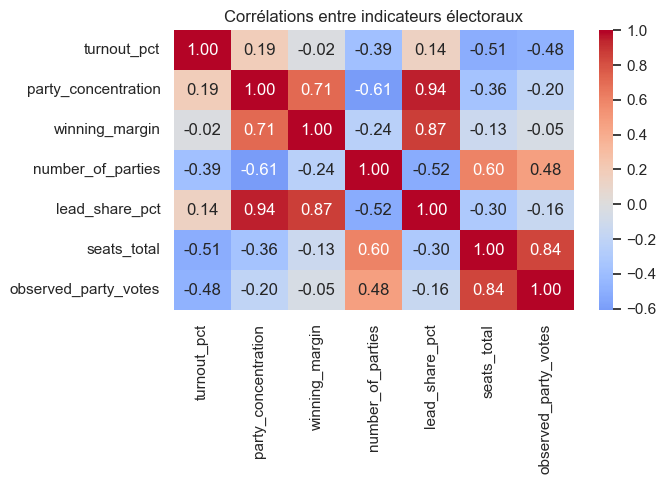

In [35]:
# Corrélations entre indicateurs
num = ["turnout_pct", "party_concentration", "winning_margin", "number_of_parties",
       "lead_share_pct", "seats_total", "observed_party_votes"]
corr = df_communes[num].corr()
display(corr)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Corrélations entre indicateurs électoraux")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlations.png", dpi=200)
plt.show()

## 5. Graphiques statistiques

### 5.0 Évolution de la participation : fichier `participation_par_annee.csv`

Attention : ce fichier contient 2011, 2016 et 2021 (élections **parlementaires**), alors que le dataset communal contient 2015 et 2021. Les deux graphiques ci-dessous ne doivent pas être confondus.

In [36]:
chemin = RESULTATS / "participation_par_annee.csv"
df_part_annee = pd.read_csv(chemin)
print(df_part_annee.columns.tolist())

# L'axe était étiqueté "%" alors que taux_moyen est une fraction (0.48, 0.45...)
if df_part_annee["taux_moyen"].max() <= 1.5:
    df_part_annee["taux_pct"] = df_part_annee["taux_moyen"] * 100
else:
    df_part_annee["taux_pct"] = df_part_annee["taux_moyen"]

display(df_part_annee)

fig = px.line(
    df_part_annee, x="annee", y="taux_pct", markers=True,
    title="Taux moyen de participation (élections parlementaires, fichier participation_par_annee.csv)",
)
fig.update_xaxes(tickmode="array", tickvals=df_part_annee["annee"], title="Année")
fig.update_yaxes(title="Taux moyen de participation (%)")
fig.update_layout(template="plotly_white")
fig.show()
save_fig(fig, "participation_par_annee_parlementaires")

['annee', 'taux_moyen', 'taux_median', 'minimum', 'maximum', 'n_circonscriptions']


,annee,taux_moyen,taux_median,minimum,maximum,n_circonscriptions,taux_pct
0,2011,0.487,0.482,0.325,0.781,92,48.700
1,2016,0.451,0.442,0.256,0.767,92,45.058
2,2021,0.540,0.581,0.198,0.851,92,54.029


PNG non exporté pour participation_par_annee_parlementaires (pip install kaleido) : ValueError


### 5.1 Histogramme de la participation par année (communales)

In [37]:
d = df_communes.dropna(subset=["turnout_pct"]).copy()
d["annee"] = d["year"].astype(str)

fig = px.histogram(
    d, x="turnout_pct", color="annee", barmode="overlay", nbins=40, opacity=0.65,
    title="Distribution du taux de participation par commune",
    labels={"turnout_pct": "Taux de participation (%)", "annee": "Année"},
)
fig.update_layout(template="plotly_white", yaxis_title="Nombre de communes")
fig.show()
save_fig(fig, "01_histogramme_participation")

PNG non exporté pour 01_histogramme_participation (pip install kaleido) : ValueError


### 5.2 Boxplot de la participation par région

In [38]:
d = df_communes.dropna(subset=["turnout_pct"]).copy()
d["annee"] = d["year"].astype(str)
ordre = d.groupby("region_name")["turnout_pct"].median().sort_values().index.tolist()

fig = px.box(
    d, x="region_name", y="turnout_pct", color="annee",
    category_orders={"region_name": ordre},
    title="Participation par région et par année",
    labels={"region_name": "Région", "turnout_pct": "Participation (%)", "annee": "Année"},
)
fig.update_layout(template="plotly_white", xaxis_tickangle=-40, height=550)
fig.show()
save_fig(fig, "02_boxplot_participation_region")

PNG non exporté pour 02_boxplot_participation_region (pip install kaleido) : ValueError


### 5.3 Communes remportées par parti

In [39]:
top = df_communes.groupby(["year", "lead_party"]).size().reset_index(name="n_communes")
top["annee"] = top["year"].astype(str)
principaux = top.groupby("lead_party")["n_communes"].sum().nlargest(12).index
top = top[top["lead_party"].isin(principaux)]
ordre = top.groupby("lead_party")["n_communes"].sum().sort_values(ascending=False).index.tolist()

fig = px.bar(
    top, x="lead_party", y="n_communes", color="annee", barmode="group",
    category_orders={"lead_party": ordre},
    title="Communes remportées par parti (12 premiers)",
    labels={"lead_party": "Parti", "n_communes": "Nombre de communes", "annee": "Année"},
)
fig.update_layout(template="plotly_white")
fig.show()
save_fig(fig, "03_communes_gagnees_par_parti")

PNG non exporté pour 03_communes_gagnees_par_parti (pip install kaleido) : ValueError


### 5.4 Parts de voix des partis (barres empilées)

Les colonnes `sap`, `sap2`, `sap3` correspondent à des listes sans appartenance politique (variantes selon l'année).

In [40]:
votes_annee = df_communes.groupby("year")[cols_votes].sum().T          # partis x années
parts = votes_annee / votes_annee.sum() * 100

top_partis = parts.max(axis=1).sort_values(ascending=False).head(10).index
plot = parts.loc[top_partis].copy()
plot.loc["AUTRES"] = parts.drop(top_partis).sum()
plot.index = [i.replace("votes_", "").upper() if i != "AUTRES" else i for i in plot.index]
plot.index.name = "parti"

plot = plot.reset_index().melt(id_vars="parti", var_name="annee", value_name="part_voix_pct")
plot["annee"] = plot["annee"].astype(str)

fig = px.bar(
    plot, x="annee", y="part_voix_pct", color="parti",
    title="Parts de voix des partis (10 premiers + autres)",
    labels={"annee": "Année", "part_voix_pct": "Part des voix (%)", "parti": "Parti"},
)
fig.update_layout(template="plotly_white", barmode="stack")
fig.show()
save_fig(fig, "04_parts_de_voix_partis")

PNG non exporté pour 04_parts_de_voix_partis (pip install kaleido) : ValueError


### 5.5 Participation vs marge de victoire

In [41]:
d = df_communes.dropna(subset=["turnout_pct"]).copy()
top8 = d["lead_party"].value_counts().nlargest(8).index
d["parti_en_tete"] = np.where(d["lead_party"].isin(top8), d["lead_party"], "Autres")
d["annee"] = d["year"].astype(str)

fig = px.scatter(
    d, x="turnout_pct", y="winning_margin", color="parti_en_tete",
    facet_col="annee", opacity=0.6, hover_name="commune_name",
    hover_data=["region_name", "lead_party"],
    title="Participation et marge de victoire par commune",
    labels={"turnout_pct": "Participation (%)", "winning_margin": "Marge de victoire",
            "parti_en_tete": "Parti en tête"},
)
fig.update_layout(template="plotly_white", height=550)
fig.show()
save_fig(fig, "05_participation_vs_marge")

PNG non exporté pour 05_participation_vs_marge (pip install kaleido) : ValueError


### 5.6 Concentration des votes vs nombre de partis

In [42]:
d = df_communes.copy()
d["annee"] = d["year"].astype(str)

fig = px.scatter(
    d, x="number_of_parties", y="party_concentration", color="annee",
    opacity=0.5, hover_name="commune_name",
    title="Concentration des votes (Herfindahl) selon le nombre de partis",
    labels={"number_of_parties": "Nombre de partis", "party_concentration": "Concentration (HHI)",
            "annee": "Année"},
)
fig.update_layout(template="plotly_white")
fig.show()
save_fig(fig, "06_concentration_vs_nb_partis")

PNG non exporté pour 06_concentration_vs_nb_partis (pip install kaleido) : ValueError


### 5.7 Profil des élus 2021 (femmes, âge, enseignement supérieur)

In [43]:
elus = df_communes.dropna(subset=["women_elected_pct"]).copy()
annee_elus = sorted(elus["year"].unique())
print("Année(s) avec profil des élus :", annee_elus)

profil_region = elus.groupby("region_name")[
    ["women_elected_pct", "elected_higher_edu_pct"]
].mean().reset_index().sort_values("women_elected_pct")

fig = px.bar(
    profil_region.melt(id_vars="region_name", var_name="indicateur", value_name="pct"),
    x="pct", y="region_name", color="indicateur", barmode="group", orientation="h",
    title="Profil des élus par région : femmes et enseignement supérieur (%)",
    labels={"pct": "Pourcentage moyen", "region_name": "Région", "indicateur": "Indicateur"},
)
fig.update_layout(template="plotly_white", height=600)
fig.show()
save_fig(fig, "07a_profil_elus_femmes_etudes")

Année(s) avec profil des élus : [np.int64(2021)]


PNG non exporté pour 07a_profil_elus_femmes_etudes (pip install kaleido) : ValueError


In [44]:
cols_age = ["elected_age_le34_pct", "elected_age_35_44_pct", "elected_age_45_54_pct", "elected_age_ge55_pct"]
noms_age = {"elected_age_le34_pct": "34 ans et moins", "elected_age_35_44_pct": "35-44 ans",
            "elected_age_45_54_pct": "45-54 ans", "elected_age_ge55_pct": "55 ans et plus"}

age = elus.groupby("region_name")[cols_age].mean().reset_index()
age = age.melt(id_vars="region_name", var_name="tranche", value_name="pct")
age["tranche"] = age["tranche"].map(noms_age)

fig = px.bar(
    age, x="region_name", y="pct", color="tranche",
    category_orders={"tranche": list(noms_age.values())},
    title="Répartition par âge des élus, par région (%)",
    labels={"region_name": "Région", "pct": "Pourcentage moyen", "tranche": "Tranche d'âge"},
)
fig.update_layout(template="plotly_white", barmode="stack", xaxis_tickangle=-40, height=550)
fig.show()
save_fig(fig, "07b_profil_elus_age")

PNG non exporté pour 07b_profil_elus_age (pip install kaleido) : ValueError


## 6. Cartographie

Prérequis : `pip install geopandas shapely plotly`

In [46]:
import geopandas as gpd
from shapely import wkt

gdf = df_communes.copy()
gdf["geometry"] = gdf["geometry_wkt"].apply(wkt.loads)
gdf = gpd.GeoDataFrame(gdf.drop(columns="geometry_wkt"), geometry="geometry", crs="EPSG:4326")

# Vérification des géométries
print("Géométries invalides :", (~gdf.geometry.is_valid).sum())
print("Géométries vides     :", gdf.geometry.is_empty.sum())
print("Types :", gdf.geometry.geom_type.value_counts().to_dict())

# Simplification : 3006 polygones détaillés sont trop lourds pour le web (0.005 degré ~ 500 m)
gdf["geometry"] = gdf.geometry.simplify(0.005, preserve_topology=True)
print("Bornes (lon min, lat min, lon max, lat max) :", gdf.total_bounds)

Géométries invalides : 0
Géométries vides     : 0
Types : {'MultiPolygon': 3006}
Bornes (lon min, lat min, lon max, lat max) : [-17.10364342  20.7708956   -0.99899673  35.92213141]


In [47]:
def carte(g, color, titre, nom_fichier, hover_extra=None, continu=True, **kwargs):
    # Choropleth interactif d'un GeoDataFrame (une ligne par commune)
    g = g.reset_index(drop=True)
    geojson = g[["geometry"]].__geo_interface__          # allégé : géométrie seule
    hover = ["region_name", "lead_party", "turnout_pct", "winning_margin"] + (hover_extra or [])
    hover = [h for h in dict.fromkeys(hover) if h in g.columns]
    data = pd.DataFrame(g.drop(columns="geometry"))

    args = dict(
        geojson=geojson, locations=data.index, color=color, hover_name="commune_name",
        hover_data=hover, center={"lat": 31.8, "lon": -7.0}, zoom=4.3, opacity=0.85, title=titre,
    )
    args.update(kwargs)
    try:
        fig = px.choropleth_map(data, map_style="carto-positron", **args)
    except AttributeError:       # anciennes versions de plotly
        fig = px.choropleth_mapbox(data, mapbox_style="carto-positron", **args)

    fig.update_traces(marker_line_width=0.2)
    fig.update_layout(margin=dict(l=0, r=0, t=50, b=0), height=700)
    fig.show()
    save_fig(fig, nom_fichier)
    return fig


annees = sorted(gdf["year"].unique())
a0, a1 = annees[0], annees[-1]
g0 = gdf[gdf["year"] == a0]
g1 = gdf[gdf["year"] == a1]
print("Années comparées :", a0, "et", a1)

Années comparées : 2015 et 2021


### 6.1 Participation

In [48]:
borne = (gdf["turnout_pct"].quantile(0.02), gdf["turnout_pct"].quantile(0.98))   # même échelle pour les deux années

_ = carte(g1.dropna(subset=["turnout_pct"]), "turnout_pct", f"Taux de participation {a1} (%)",
          f"carte_participation_{a1}", color_continuous_scale="Viridis", range_color=borne)
_ = carte(g0.dropna(subset=["turnout_pct"]), "turnout_pct", f"Taux de participation {a0} (%)",
          f"carte_participation_{a0}", color_continuous_scale="Viridis", range_color=borne)

PNG non exporté pour carte_participation_2021 (pip install kaleido) : ValueError


PNG non exporté pour carte_participation_2015 (pip install kaleido) : ValueError


### 6.2 Parti en tête

In [49]:
g = g1.copy()
top8 = g["lead_party"].value_counts().nlargest(8).index
g["parti_en_tete"] = np.where(g["lead_party"].isin(top8), g["lead_party"], "Autres")

_ = carte(g, "parti_en_tete", f"Parti en tête par commune ({a1})", f"carte_parti_en_tete_{a1}",
          color_discrete_sequence=px.colors.qualitative.Safe + ["#999999"])

PNG non exporté pour carte_parti_en_tete_2021 (pip install kaleido) : ValueError


### 6.3 Marge de victoire et concentration des votes

In [50]:
_ = carte(g1, "winning_margin", f"Marge de victoire {a1} (écart 1er - 2e)", f"carte_marge_{a1}",
          color_continuous_scale="Magma", range_color=(0, 0.6))
_ = carte(g1, "party_concentration", f"Concentration des votes {a1} (Herfindahl)", f"carte_concentration_{a1}",
          color_continuous_scale="Cividis", hover_extra=["number_of_parties"])

PNG non exporté pour carte_marge_2021 (pip install kaleido) : ValueError


PNG non exporté pour carte_concentration_2021 (pip install kaleido) : ValueError


### 6.4 Changement de parti en tête entre les deux scrutins

In [51]:
piv = df_communes.pivot_table(index="commune_code", columns="year", values="lead_party", aggfunc="first")
piv = piv.dropna(subset=[a0, a1]).copy()
piv["statut"] = np.where(piv[a0] == piv[a1], "Inchangé", "Changé")
piv["transition"] = piv[a0].astype(str) + " -> " + piv[a1].astype(str)

print(f"Communes présentes aux deux scrutins : {len(piv)}")
print(piv["statut"].value_counts(normalize=True).mul(100).round(1).astype(str) + " %")

print("\nTransitions les plus fréquentes :")
display(piv[piv["statut"] == "Changé"]["transition"].value_counts().head(10))

g_change = g1.merge(piv[["statut", "transition"]], left_on="commune_code", right_index=True, how="inner")
_ = carte(g_change, "statut", f"Changement de parti en tête, {a0} -> {a1}", "carte_changement_parti",
          hover_extra=["transition"],
          color_discrete_map={"Inchangé": "#bdbdbd", "Changé": "#d62728"})

Communes présentes aux deux scrutins : 1503
statut
Changé      65.6 %
Inchangé    34.4 %
Name: proportion, dtype: str

Transitions les plus fréquentes :


transition
PAM -> RNI     128
PI -> RNI       81
PJD -> RNI      67
PAM -> PI       57
MP -> RNI       55
USFP -> RNI     42
PI -> PAM       38
PJD -> PAM      34
RNI -> PAM      33
USFP -> PAM     32
Name: count, dtype: int64

PNG non exporté pour carte_changement_parti (pip install kaleido) : ValueError


## 7. Export pour le dashboard Streamlit

In [52]:
# GeoJSON simplifié (évite de reparser le WKT à chaque lancement de l'app)
export = g1[["commune_code", "commune_name", "region_name", "province_name", "geometry"]].copy()
export.to_file(DATA_PROCESSED / "communes.geojson", driver="GeoJSON")
print("GeoJSON exporté :", DATA_PROCESSED / "communes.geojson")
print("Taille (Mo) :", round((DATA_PROCESSED / "communes.geojson").stat().st_size / 1e6, 2))

# Table plate (sans géométrie) pour Streamlit
df_communes.drop(columns=["geometry_wkt"]).to_csv(DATA_PROCESSED / "communes_sans_geometrie.csv", index=False)
print("CSV sans géométrie exporté")

print("\nFigures produites :")
for f in sorted(FIG_DIR.glob("*.html")):
    print(" -", f.name)

GeoJSON exporté : c:\Users\DELL\Desktop\Projet-Election\Data\processed\communes.geojson
Taille (Mo) : 1.67
CSV sans géométrie exporté

Figures produites :
 - 01_histogramme_participation.html
 - 02_boxplot_participation_region.html
 - 03_communes_gagnees_par_parti.html
 - 04_parts_de_voix_partis.html
 - 05_participation_vs_marge.html
 - 06_concentration_vs_nb_partis.html
 - 07a_profil_elus_femmes_etudes.html
 - 07b_profil_elus_age.html
 - carte_changement_parti.html
 - carte_concentration_2021.html
 - carte_marge_2021.html
 - carte_parti_en_tete_2021.html
 - carte_participation_2015.html
 - carte_participation_2021.html
 - participation_par_annee_parlementaires.html


## Synthèse

- Le dataset communal couvre deux scrutins (2015 et 2021). Les NaN sur les colonnes de partis et le profil des élus sont **structurels**.
- Le fichier `participation_par_annee.csv` concerne les élections parlementaires et ne se compare pas directement au dataset communal.
- Les figures sont dans `Script/resultats/figures/`, le GeoJSON et le dictionnaire dans `Data/processed/`.
- **Prochaine étape** : créer `src/visualization.py` et le dashboard `dashboard/app.py` en réutilisant ces fonctions, puis brancher les sorties ML (`models/metrics.csv`, `predictions.csv`, `feature_importance.csv`).